# Exercise 1 — Predicting an unknown endpoint

Exercise sheet 1, practical work part II (a–c).

Full training consists of twelve full-batch runs.


Settings used and adapted from `SLT_Neural_Networks_Epsilon_Loss.ipynb`. **Adaptation:**

## Shared setup

Imports, training settings and plot styling.

In [1]:
import time
from typing import TypeAlias, cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from numpy.typing import NDArray

FloatArray: TypeAlias = NDArray[np.float64]
HiddenLayers: TypeAlias = tuple[int, ...]

# sheet settings
N: int = 10 # Input
N_TRAIN: int = 10_000 # training data
ARCHITECTURES: list[HiddenLayers] = [(16,), (64,), (32, 32), (64, 64, 32)] # neural network architectures (hidden layers)

# taken from the example notebooks
EPOCHS: int = 4000
LEARNING_RATE: float = 0.003
INIT_SEEDS: list[int] = [11, 22, 33]
DATA_SEED: int = 7

# matplotlib settings (mainly taken from the example notebooks)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})

print ("Settings configured!")


Settings configured!


## II(a) — The endpoint population

Following Part I. 2, generate each example in two steps:

1. Draw the endpoint $L \sim \mathrm{Uniform}[1,5]$.
2. Given this $L$, draw $N = 10$ independent observations uniformly from $[0,L]$.

**Input:** the $N$ observations, sorted in ascending order.

**Target:** the endpoint $L$.

Repeat these steps independently to obtain $m = 10{,}000$ training examples, as required in Part II(a). All four architectures use the same training set.

In [2]:
def sample_examples(
    m: int, random_generator: np.random.Generator
) -> tuple[FloatArray, FloatArray]:
    """Generate examples for training or testing.

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: random generator for endpoints and observations.
    :return: Sorted inputs of shape (m, N) and endpoint labels of shape (m,).
        Each endpoint is drawn uniformly from [1, 5]. Conditional on that
        endpoint, the N observations are independent uniform draws from [0, L].
    """
    labels: FloatArray = random_generator.uniform(1.0, 5.0, m)
    uniform_samples: FloatArray = random_generator.uniform(size=(m, N))
    endpoints_column: FloatArray = labels.reshape(m, 1)
    inputs: FloatArray = uniform_samples * endpoints_column
    return np.sort(inputs, axis=1), labels


def mse(y: FloatArray, predictions: FloatArray) -> float:
    """Compute the empirical mean squared prediction error.

    :param y: One-dimensional NumPy array of true labels, shape (m,).
    :param predictions: One-dimensional NumPy array of predictions,
        with the same shape as y. No conversion or reshaping is performed.
    :return: Average squared difference as a float.
    :raises ValueError: If inputs are not one-dimensional, have different
        shapes, or contain no examples.
    """
    if y.ndim != 1 or y.shape != predictions.shape or y.size == 0:
        raise ValueError('Expected non-empty 1D arrays of the same shape.')
    return float(np.mean((y - predictions) ** 2))


# Allocate the training stream now; later tasks get separate child streams.
seed_sequence: np.random.SeedSequence = np.random.SeedSequence(DATA_SEED)
training_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]
X_train: FloatArray
y_train: FloatArray
X_train, y_train = sample_examples(N_TRAIN, np.random.default_rng(training_stream))

assert X_train.shape == (N_TRAIN, N) and y_train.shape == (N_TRAIN,)
assert np.all(np.diff(X_train, axis=1) >= 0)
assert np.all((X_train >= 0) & (X_train <= y_train[:, None]))
assert np.all((y_train >= 1) & (y_train <= 5))
print('Training:', X_train.shape, '| Label range:', y_train.min(), y_train.max())
display(pd.DataFrame(X_train[:3], columns=[f'u{i+1}' for i in range(N)])
        .assign(L=y_train[:3]).round(3))

Training: (10000, 10) | Label range: 1.000001149171522 4.999787752448674


,u1,u2,u3,u4,u5,u6,u7,u8,u9,u10,L
0,0.391,0.881,0.958,1.884,1.983,2.077,2.711,2.874,3.407,4.131,4.191
1,0.114,0.123,0.166,0.182,0.198,0.314,0.492,1.016,1.147,1.190,1.212
2,0.001,0.245,0.499,1.400,1.662,1.703,2.429,2.875,2.897,2.957,3.365


In [3]:
# NumPy network and Adam follow the course template; gradient adapted for MSE.
class Network:
    def __init__(self, hidden: HiddenLayers, seed: int) -> None:
        rng: np.random.Generator = np.random.default_rng(seed)
        sizes: tuple[int, ...] = (N,) + tuple(hidden) + (1,)
        self.W: list[FloatArray] = [rng.normal(size=(a, b)) * np.sqrt(2 / (a + b))
                  for a, b in zip(sizes[:-1], sizes[1:])]
        self.b: list[FloatArray] = [np.zeros((1, b)) for b in sizes[1:]]

    def forward(self, X: FloatArray) -> list[FloatArray]:
        acts: list[FloatArray] = [X]
        for j, (W, b) in enumerate(zip(self.W, self.b)):
            z = acts[-1] @ W + b
            acts.append(np.tanh(z) if j < len(self.W) - 1 else z)
        return acts

    def predict(self, X: FloatArray) -> FloatArray:
        return self.forward(X)[-1].ravel()

    def gradients(self, X: FloatArray, y: FloatArray) -> list[FloatArray]:
        acts: list[FloatArray] = self.forward(X)
        delta: FloatArray = 2 * (acts[-1] - np.asarray(y).reshape(-1, 1)) / len(X)
        gW: list[FloatArray | None] = [None] * len(self.W)
        gb: list[FloatArray | None] = [None] * len(self.b)
        for j in reversed(range(len(self.W))):
            gW[j] = acts[j].T @ delta
            gb[j] = delta.sum(axis=0, keepdims=True)
            if j > 0:
                delta = (delta @ self.W[j].T) * (1 - acts[j] ** 2)
        # The loop fills every placeholder before returning.
        return cast(list[FloatArray], gW + gb)

    def copy_parameters(self) -> list[FloatArray]:
        return [p.copy() for p in self.W + self.b]

    def set_parameters(self, values: list[FloatArray]) -> None:
        for param, value in zip(self.W + self.b, values):
            param[:] = value

def architecture_name(hidden: HiddenLayers) -> str:
    return ' → '.join(map(str, (N,) + tuple(hidden) + (1,)))

TrainingResult: TypeAlias = tuple[Network, float, int, FloatArray]

def train(hidden: HiddenLayers, seed: int) -> TrainingResult:
    net: Network = Network(hidden, seed)
    params: list[FloatArray] = net.W + net.b
    moment: list[FloatArray] = [np.zeros_like(p) for p in params]
    variance: list[FloatArray] = [np.zeros_like(p) for p in params]
    best_loss: float = np.inf
    best_parameters: list[FloatArray] | None = None
    best_epoch: int = 0
    history: list[tuple[int, float]] = []
    for epoch in range(1, EPOCHS + 1):
        gradients = net.gradients(X_train, y_train)
        for j, (param, grad) in enumerate(zip(params, gradients)):
            moment[j] = 0.9 * moment[j] + 0.1 * grad
            variance[j] = 0.999 * variance[j] + 0.001 * grad ** 2
            param -= LEARNING_RATE * (moment[j] / (1 - 0.9 ** epoch)) / (
                np.sqrt(variance[j] / (1 - 0.999 ** epoch)) + 1e-8)
        loss = mse(y_train, net.predict(X_train))
        if not np.isfinite(loss):
            raise FloatingPointError(f'Non-finite training loss: {hidden}, {seed}')
        if loss < best_loss:
            best_loss, best_parameters, best_epoch = loss, net.copy_parameters(), epoch
        if epoch == 1 or epoch % 100 == 0:
            history.append((epoch, loss))
    # Positive EPOCHS and finite losses ensure a checkpoint was saved.
    net.set_parameters(cast(list[FloatArray], best_parameters))
    return net, best_loss, best_epoch, np.asarray(history)

# Small numerical gradient check before the expensive training runs.
probe: Network = Network((3,), seed=123)
params: list[FloatArray] = probe.W + probe.b
analytic: list[FloatArray] = probe.gradients(X_train[:4], y_train[:4])
for param, grad in zip(params, analytic):
    index = (0, 0)
    old, step = param[index], 1e-6
    param[index] = old + step
    plus = mse(y_train[:4], probe.predict(X_train[:4]))
    param[index] = old - step
    minus = mse(y_train[:4], probe.predict(X_train[:4]))
    param[index] = old
    np.testing.assert_allclose(grad[index], (plus - minus) / (2 * step), rtol=1e-4, atol=1e-6)
print('MSE gradient check passed.')

MSE gradient check passed.


In [4]:
from concurrent.futures import ThreadPoolExecutor, as_completed

# Parallelize independent runs only; batch size and epoch count are unchanged.
# Set to 1 if memory is limited or the CPU is slow.
MAX_WORKERS: int = 3
models: dict[str, Network] = {}
histories: dict[str, FloatArray] = {}
runs: list[dict[str, str | int | float]] = []
selected_runs: dict[str, dict[str, int]] = {}
trials: dict[tuple[HiddenLayers, int], TrainingResult] = {}
started: float = time.perf_counter()
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    jobs = {pool.submit(train, hidden, seed): (hidden, seed)
            for hidden in reversed(ARCHITECTURES) for seed in INIT_SEEDS}
    for job in as_completed(jobs):
        hidden, seed = jobs[job]
        net, loss, best_epoch, history = job.result()
        trials[(hidden, seed)] = (net, loss, best_epoch, history)
        print(f'{architecture_name(hidden)}, Seed {seed}: Train-MSE {loss:.6f}', flush=True)
for hidden in ARCHITECTURES:
    name = architecture_name(hidden)
    for seed in INIT_SEEDS:
        net, loss, best_epoch, history = trials[(hidden, seed)]
        runs.append({'Model': name, 'Seed': seed, 'Train-MSE': loss,
                     'Best training epoch': best_epoch})
    seed = min(INIT_SEEDS, key=lambda s: trials[(hidden, s)][1])
    net, loss, best_epoch, history = trials[(hidden, seed)]
    models[name], histories[name] = net, history
    selected_runs[name] = {'Seed': seed, 'Epoch': best_epoch}
assert len(models) == 4
print(f'Training time: {(time.perf_counter() - started) / 60:.1f} min')
display(pd.DataFrame(runs).round(6))

10 → 64 → 64 → 32 → 1, Seed 33: Train-MSE 0.081209


10 → 64 → 64 → 32 → 1, Seed 22: Train-MSE 0.081340


10 → 64 → 64 → 32 → 1, Seed 11: Train-MSE 0.081264


10 → 32 → 32 → 1, Seed 11: Train-MSE 0.081592


10 → 32 → 32 → 1, Seed 22: Train-MSE 0.081487


...

10 → 16 → 1, Seed 11: Train-MSE 0.081995


10 → 16 → 1, Seed 22: Train-MSE 0.081993


10 → 16 → 1, Seed 33: Train-MSE 0.081961


Training time: 7.3 min


,Model,Seed,Train-MSE,Best training epoch
0,10 → 16 → 1,11,0.081995,4000
1,10 → 16 → 1,22,0.081993,4000
2,10 → 16 → 1,33,0.081961,4000
3,10 → 64 → 1,11,0.081731,4000
4,10 → 64 → 1,22,0.081637,4000
5,10 → 64 → 1,33,0.081791,4000
6,10 → 32 → 32 → 1,11,0.081592,4000
7,10 → 32 → 32 → 1,22,0.081487,4000
8,10 → 32 → 32 → 1,33,0.081573,4000
9,10 → 64 → 64 → 32 → 1,11,0.081264,4000


## II(b) — Training and independent testing

All seven rules are evaluated on the same 20,000 fresh test examples. Theory from I.2(b): h1 = 31/90, h2 = 31/198, h3 = 31/360. Standard errors refer to the test MSE conditional on the fitted networks, not to variation across new training runs.

In [5]:
def baselines(X: FloatArray) -> dict[str, FloatArray]:
    """Predict endpoints using the three rules specified in Task I.1.

    :param X: NumPy array of shape (m, N), one observation vector per row;
        sorting is not required. N is the global input size.
    :return: Dictionary mapping h1, h2 and h3 to predictions of shape
        (m,): twice the row mean, the row maximum, and (N + 1) / N
        times the row maximum, respectively.
    """
    maximum: FloatArray = X.max(axis=1)
    return {'h1': 2 * X.mean(axis=1), 'h2': maximum,
            'h3': ((N + 1) / N) * maximum}


def theoretical_risks(L_squared: float) -> dict[str, float]:
    """Evaluate the exact population risks derived in Part I.

    :param L_squared: L**2 for a fixed endpoint (Task I.1), or
        E[L**2] = 31/3 for L uniform on [1, 5] (Task I.2).
    :return: Dictionary of exact risks for h1, h2 and h3, using the
        global number N of observations per input vector.
    """
    return {'h1': L_squared / (3 * N),
            'h2': 2 * L_squared / ((N + 1) * (N + 2)),
            'h3': L_squared / (N * (N + 2))}


# Sorting must not change the three symmetric comparison rules.
for name, pred in baselines(X_train[:, ::-1]).items():
    np.testing.assert_allclose(pred, baselines(X_train)[name])

,Train-MSE,Test-MSE,Test-SE,Theory
Model,,,,
10 → 16 → 1,0.081961,0.079010,0.001578,NaN
10 → 64 → 1,0.081637,0.078817,0.001571,NaN
10 → 32 → 32 → 1,0.081487,0.078654,0.001570,NaN
10 → 64 → 64 → 32 → 1,0.081209,0.078639,0.001569,NaN
h1,0.355208,0.344141,0.004358,0.344444
h2,0.164297,0.158839,0.002627,0.156566
h3,0.092485,0.088228,0.001714,0.086111


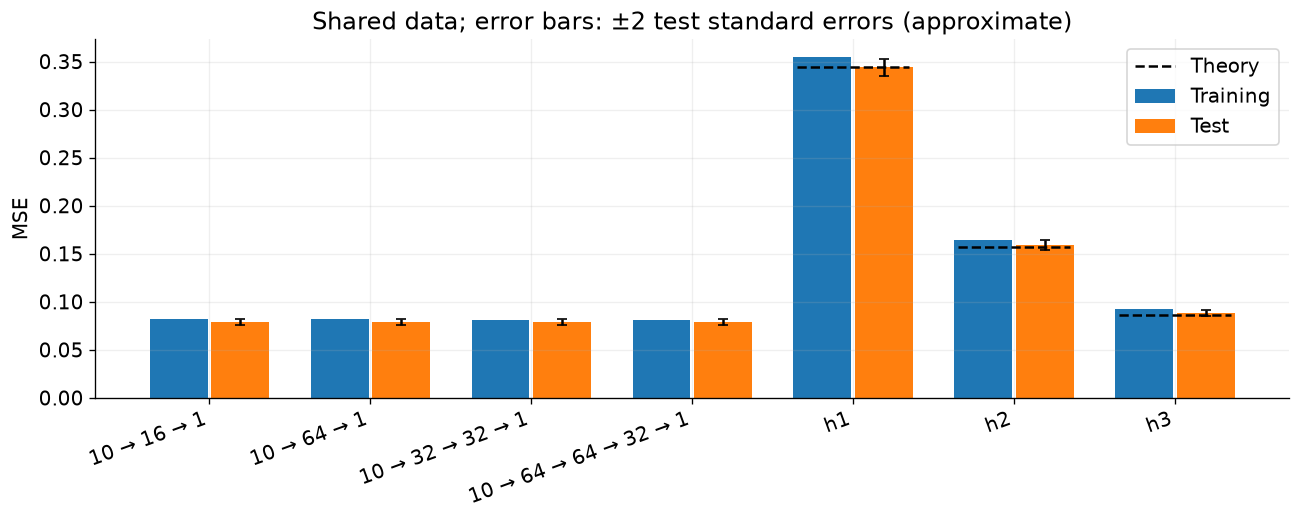

,Rule,Test minus theory,Difference / Test-SE
0,h1,-0.000,-0.070
1,h2,0.002,0.865
2,h3,0.002,1.235


In [6]:
N_TEST: int = 20_000
test_stream: np.random.SeedSequence = seed_sequence.spawn(1)[0]
X_test: FloatArray
y_test: FloatArray
X_test, y_test = sample_examples(N_TEST, np.random.default_rng(test_stream))
assert X_test.shape == (20_000, 10)
train_predictions: dict[str, FloatArray] = {name: net.predict(X_train) for name, net in models.items()}
test_predictions: dict[str, FloatArray] = {name: net.predict(X_test) for name, net in models.items()}
train_predictions.update(baselines(X_train))
test_predictions.update(baselines(X_test))
theory: dict[str, float] = theoretical_risks(31 / 3)
rows: list[dict[str, str | float | np.float64]] = []
for name in train_predictions:
    losses = (test_predictions[name] - y_test) ** 2
    assert np.all(np.isfinite(losses))
    rows.append({'Model': name, 'Train-MSE': mse(y_train, train_predictions[name]),
                 'Test-MSE': losses.mean(), 'Test-SE': losses.std(ddof=1) / np.sqrt(N_TEST),
                 'Theory': theory.get(name, np.nan)})
comparison: pd.DataFrame = pd.DataFrame(rows).set_index('Model')
assert comparison.shape[0] == 7
display(comparison.round(6))

fig, ax = plt.subplots(figsize=(11, 4.5))
positions = np.arange(len(comparison))
ax.bar(positions - 0.19, comparison['Train-MSE'], width=0.36, label='Training')
ax.bar(positions + 0.19, comparison['Test-MSE'], width=0.36, label='Test',
       yerr=2 * comparison['Test-SE'], capsize=3)
for i, name in enumerate(comparison.index):
    if name in theory:
        ax.plot([i - 0.35, i + 0.35], [theory[name]] * 2, color='black',
                linestyle='--', label='Theory' if name == 'h1' else None)
ax.set_xticks(positions, comparison.index, rotation=20, ha='right')
ax.set(ylabel='MSE', title='Shared data; error bars: ±2 test standard errors (approximate)')
ax.legend()
plt.tight_layout()
plt.show()

# Compare theoretical formulas with Monte Carlo estimates.
checks: list[dict[str, str | float | np.float64]] = []
for name in theory:
    se = comparison.loc[name, 'Test-SE']
    checks.append({'Rule': name, 'Test minus theory': comparison.loc[name, 'Test-MSE'] - theory[name],
                   'Difference / Test-SE': (comparison.loc[name, 'Test-MSE'] - theory[name]) / se})
display(pd.DataFrame(checks).round(3))

In [7]:
best_net = comparison.loc[list(models), 'Test-MSE'].idxmin()
best_baseline = comparison.loc[list(theory), 'Test-MSE'].idxmin()
train_gap = comparison.loc[best_net, 'Test-MSE'] - comparison.loc[best_net, 'Train-MSE']
lines: list[str] = [
    '### II(b) — Brief discussion',
    f'- In this run, **{best_net}** has the lowest test MSE among the networks '
    f'({comparison.loc[best_net, "Test-MSE"]:.5f}); among h1–h3, it is **{best_baseline}** '
    f'({comparison.loc[best_baseline, "Test-MSE"]:.5f}). This is a retrospective comparison, not test-based tuning.',
    f'- For this network, test MSE minus training MSE is **{train_gap:.5f}**. '
    'The tables allow a direct comparison of architectures; larger networks need not perform better under the same optimization budget.',
    '- For h1–h3, empirical MSE values are compared with the exact risks. '
    'Differences are expected with finite samples; their size is reported in test standard errors.',
]
display(Markdown((chr(10) * 2).join(lines)))

### II(b) — Brief discussion

- In this run, **10 → 64 → 64 → 32 → 1** has the lowest test MSE among the networks (0.07864); among h1–h3, it is **h3** (0.08823). This is a retrospective comparison, not test-based tuning.

- For this network, test MSE minus training MSE is **-0.00257**. The tables allow a direct comparison of architectures; larger networks need not perform better under the same optimization budget.

- For h1–h3, empirical MSE values are compared with the exact risks. Differences are expected with finite samples; their size is reported in test standard errors.

## II(c) — Fixed L and distribution shift

For each L, generate 5,000 fresh input vectors and use the same vectors for all seven rules. The four trained networks remain unchanged. Dashed curves show the exact risks from I.1(b); the shaded region marks the training range [1,5].

In [8]:
N_FIXED: int = 5_000
L_VALUES: FloatArray = np.array([0.5, 1, 2, 3, 4, 5, 6, 8])


def sample_fixed_endpoint(
    m: int, random_generator: np.random.Generator, fixed_L: float
) -> tuple[FloatArray, FloatArray]:
    """Generate fresh observation vectors for a fixed endpoint in Task II(c).

    :param m: Number of complete examples, each containing N observations.
    :param random_generator: NumPy random generator for the observations.
    :param fixed_L: Positive endpoint shared by all examples.
    :return: Sorted inputs of shape (m, N) and labels of shape (m,),
        all equal to fixed_L. Each observation is drawn uniformly from [0, fixed_L].
    """
    labels: FloatArray = np.full(m, fixed_L, dtype=float)
    inputs: FloatArray = random_generator.uniform(size=(m, N)) * labels[:, None]
    return np.sort(inputs, axis=1), labels


fixed_streams: list[np.random.SeedSequence] = seed_sequence.spawn(len(L_VALUES))

Model,10 → 16 → 1,10 → 32 → 32 → 1,10 → 64 → 1,10 → 64 → 64 → 32 → 1,h1,h2,h3
L,,,,,,,
0.5,0.00352,0.05739,0.02193,0.18441,0.00815,0.00368,0.00203
1.0,0.01091,0.01282,0.01196,0.01334,0.03270,0.01471,0.00811
2.0,0.03735,0.03737,0.03762,0.03835,0.12936,0.06107,0.03380
3.0,0.08339,0.08544,0.08511,0.08380,0.30599,0.14516,0.07974
4.0,0.10877,0.10526,0.10402,0.10803,0.52086,0.24425,0.13336
5.0,0.19267,0.19120,0.19060,0.19085,0.82332,0.38426,0.21063
6.0,0.79682,0.69028,0.60290,0.79716,1.20417,0.55667,0.30536
8.0,5.53145,4.75515,3.77318,5.85162,2.12648,0.94447,0.52101


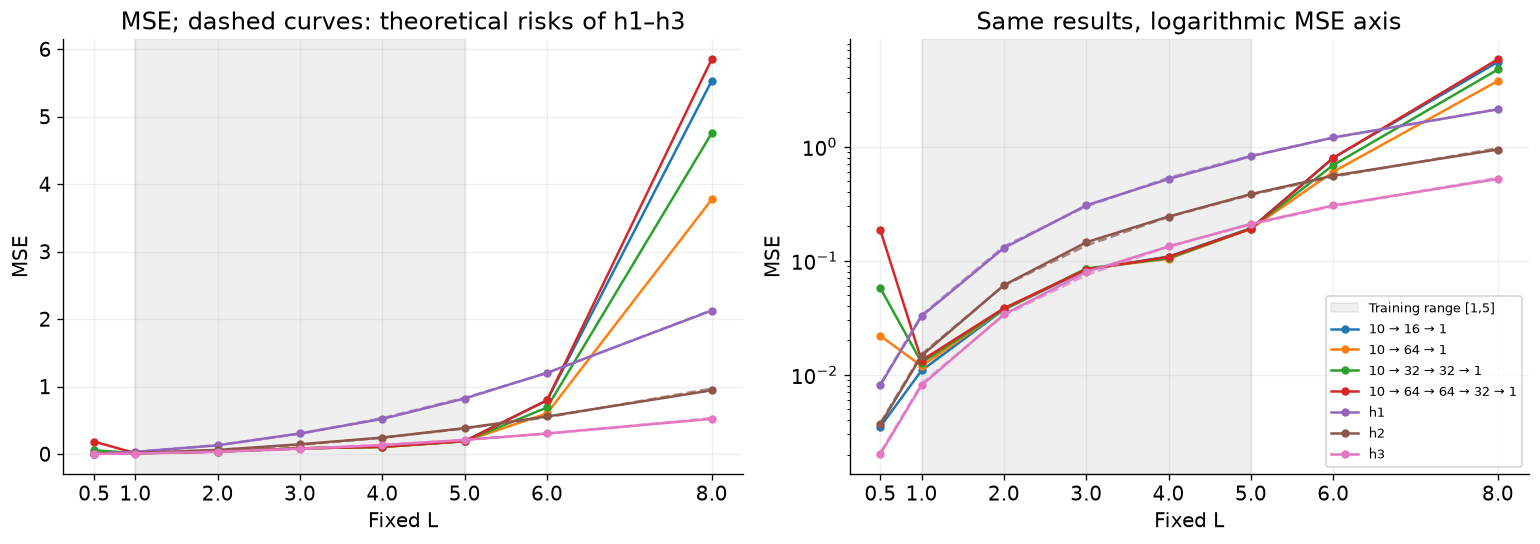

Check passed: no network was modified during the fixed-L evaluation.


In [9]:
frozen_parameters: dict[str, list[FloatArray]] = {name: net.copy_parameters() for name, net in models.items()}
fixed_rows: list[dict[str, str | float | np.float64]] = []
X_fixed: FloatArray
y_fixed: FloatArray
for L, stream in zip(L_VALUES, fixed_streams):
    X_fixed, y_fixed = sample_fixed_endpoint(N_FIXED, np.random.default_rng(stream), fixed_L=L)
    assert X_fixed.shape == (5_000, 10)
    predictions: dict[str, FloatArray] = {name: net.predict(X_fixed) for name, net in models.items()}
    predictions.update(baselines(X_fixed))
    exact = theoretical_risks(L ** 2)
    for name, pred in predictions.items():
        losses = (pred - y_fixed) ** 2
        fixed_rows.append({'L': L, 'Model': name, 'MSE': losses.mean(),
                           'SE': losses.std(ddof=1) / np.sqrt(N_FIXED),
                           'Theory': exact.get(name, np.nan)})
for name, net in models.items():
    for before, after in zip(frozen_parameters[name], net.W + net.b):
        np.testing.assert_array_equal(before, after)
fixed_results: pd.DataFrame = pd.DataFrame(fixed_rows)
fixed_table: pd.DataFrame = fixed_results.pivot(index='L', columns='Model', values='MSE')
assert fixed_table.shape == (8, 7)
display(fixed_table.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
for ax in axes:
    ax.axvspan(1, 5, color='grey', alpha=0.12, label='Training range [1,5]')
    for name in comparison.index:
        data = fixed_results[fixed_results.Model == name]
        line, = ax.plot(data.L, data.MSE, 'o-', label=name, markersize=4)
        if name in theory:
            ax.plot(data.L, data.Theory, '--', color=line.get_color(), alpha=0.7)
    ax.set(xlabel='Fixed L', ylabel='MSE', xticks=L_VALUES)
axes[0].set_title('MSE; dashed curves: theoretical risks of h1–h3')
axes[1].set_yscale('log')
axes[1].set_title('Same results, logarithmic MSE axis')
axes[1].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()
print('Check passed: no network was modified during the fixed-L evaluation.')

In [10]:
lines: list[str] = [
    '### II(c) — Brief discussion',
    '- For L = 1, 2, 3, 4, 5, the data-generating mechanism stays within the training range. '
    'Fixed-L errors need not be equal throughout that range.',
    '- L = 0.5, 6 and 8 lie outside the training distribution. '
    'The algebraic rules scale with L, so their theoretical L² risk scaling also holds there. '
    'The tanh networks do not have this scaling property and must extrapolate; good test performance on [1,5] does not guarantee good extrapolation.',
]
for L in [0.5, 6.0, 8.0]:
    row = fixed_table.loc[L]
    lines.append(f'- At L = {L:g}: MSE of {best_net} = **{row[best_net]:.5f}**, '
                 f'MSE of h3 = **{row["h3"]:.5f}**.')
lines.append('**Submission:** Review the tables, plots and this brief discussion; include the main results '
             'together with `theorie.md` in the required theory/discussion PDF. '
             'Submit the executable notebook separately as an `.ipynb` file.')
display(Markdown((chr(10) * 2).join(lines)))

### II(c) — Brief discussion

- For L = 1, 2, 3, 4, 5, the data-generating mechanism stays within the training range. Fixed-L errors need not be equal throughout that range.

- L = 0.5, 6 and 8 lie outside the training distribution. The algebraic rules scale with L, so their theoretical L² risk scaling also holds there. The tanh networks do not have this scaling property and must extrapolate; good test performance on [1,5] does not guarantee good extrapolation.

- At L = 0.5: MSE of 10 → 64 → 64 → 32 → 1 = **0.18441**, MSE of h3 = **0.00203**.

- At L = 6: MSE of 10 → 64 → 64 → 32 → 1 = **0.79716**, MSE of h3 = **0.30536**.

- At L = 8: MSE of 10 → 64 → 64 → 32 → 1 = **5.85162**, MSE of h3 = **0.52101**.

**Submission:** Review the tables, plots and this brief discussion; include the main results together with `theorie.md` in the required theory/discussion PDF. Submit the executable notebook separately as an `.ipynb` file.